<a href="https://colab.research.google.com/github/Jesus-0655/Satelites_Actividad_IA_LITIID74/blob/main/AstroShield_LITIID74_Equipo_Dinamita.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## AstroShield — Motor Lógico y Optimización de la Constelación
Aqui esta toda la lógica matemática del modelo planetario, el sistema de coordenadas,
el cálculo de cobertura por muestreo, el mecanismo de reparación de restricciones y el algoritmo evolutivo completo.
Jesus.

In [7]:
import numpy as np
import math
import time
import json

# --- CONSTANTES GLOBALES Y MODELO ---
R_EARTH = 6371.0                  # Radio de la Tierra (km)
SAT_FOOTPRINT_RADIUS_KM = 1490.0  # Radio de la huella física proyectada de cada satélite (km, ≈13.4° de arco)
REGION_RADIUS_KM = 300.0          # Radio de observación de cada región alrededor de su centro (km)
LIMIT_SEPARATION_DEG = 5.0        # Separación mínima entre satélites

# --- DATOS DE REGIONES DE INTERÉS ---
REGIONS = [
    {"name": "Península de Yucatán, México", "lat": 20.5, "lon": -89.0, "priority_weight": 3},
    {"name": "Amazonía brasileña", "lat": -3.5, "lon": -62.0, "priority_weight": 3},
    {"name": "California, Estados Unidos", "lat": 36.8, "lon": -119.4, "priority_weight": 2},
    {"name": "Región del Sahel, África", "lat": 15.0, "lon": 0.0, "priority_weight": 2},
    {"name": "Japón", "lat": 36.0, "lon": 138.0, "priority_weight": 2},
    {"name": "Interior de Australia", "lat": -25.0, "lon": 133.0, "priority_weight": 1}
]

# --- RESTRICCIONES ESPACIALES ---
FORBIDDEN_ZONES = [
    # Zonas de desechos espaciales
    {"name": "Atlántico Norte", "lat": 45.0, "lon": -35.0, "radius": 12.0},
    {"name": "Pacífico Sur", "lat": -30.0, "lon": -120.0, "radius": 10.0},
    {"name": "Región polar norte", "lat": 78.0, "lon": 30.0, "radius": 8.0},
    # Posiciones ocupadas
    {"name": "Objeto A", "lat": 10.0, "lon": 45.0, "radius": 5.0},
    {"name": "Objeto B", "lat": -15.0, "lon": 110.0, "radius": 5.0}
]

# --- FUNCIONES GEOMÉTRICAS ---
def haversine_distance_deg(lat1, lon1, lat2, lon2):
    """Distancia angular (grados) entre dos coordenadas esféricas."""
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    delta_phi = math.radians(lat2 - lat1)
    delta_lambda = math.radians(lon2 - lon1)
    a = math.sin(delta_phi/2.0)**2 + math.cos(phi1)*math.cos(phi2)*math.sin(delta_lambda/2.0)**2
    c = 2.0 * math.atan2(math.sqrt(a), math.sqrt(1.0 - a))
    return math.degrees(c)

def great_circle_km(lat1, lon1, lat2, lon2):
    """Distancia ortodrómica real en kilómetros sobre la superficie terrestre."""
    return R_EARTH * math.radians(haversine_distance_deg(lat1, lon1, lat2, lon2))

def wrap_longitude(lon):
    """Ajusta la longitud al rango [-180, 180]."""
    return (lon + 180.0) % 360.0 - 180.0

def sample_sphere_point_uniform():
    """Punto uniforme en la esfera (arcsin evita acumulación en polos)."""
    lon = np.random.uniform(-180.0, 180.0)
    lat = math.degrees(math.asin(np.random.uniform(-1.0, 1.0)))
    return lat, lon

# Implementar validación y reparación de posición en zonas restringidas
Julian.

In [8]:
def is_inside_restricted_zone(lat, lon):
    """Verifica si un punto cae dentro de alguna zona restringida u objeto ocupado."""
    for zone in FORBIDDEN_ZONES:
        dist = haversine_distance_deg(lat, lon, zone["lat"], zone["lon"])
        if dist <= zone["radius"]:
            return True, zone, dist
    return False, None, 0.0

def repair_satellite(lat, lon):
    """Aplica el algoritmo de reparación para empujar el satélite hacia los bordes."""
    current_lat, current_lon = lat, lon
    for attempt in range(10):
        inside, zone, dist = is_inside_restricted_zone(current_lat, current_lon)
        if not inside:
            return current_lat, current_lon

        # Empujar a lo largo del círculo máximo alejándolo del centro de la zona
        d_lat = current_lat - zone["lat"]
        d_lon = wrap_longitude(current_lon - zone["lon"])
        norm = math.sqrt(d_lat**2 + d_lon**2)
        if norm < 1e-6:
            # Si coincide exactamente con el centro, aplicamos un empuje aleatorio
            d_lat, d_lon = np.random.uniform(-1, 1), np.random.uniform(-1, 1)
            norm = math.sqrt(d_lat**2 + d_lon**2)

        # Mover al límite de la zona + 0.5 grados de margen
        push_factor = (zone["radius"] + 0.5) / (norm if norm > 0 else 1.0)
        current_lat = np.clip(zone["lat"] + d_lat * push_factor, -90.0, 90.0)
        current_lon = wrap_longitude(zone["lon"] + d_lon * push_factor)

    # Si falla 10 veces, se reubica totalmente al azar de forma uniforme
    return sample_sphere_point_uniform()

def process_and_repair_individual(coords):
    """Repara cada satélite de forma individual e independiente en un cromosoma (8 pares)."""
    repaired = []
    for i in range(8):
        lat, lon = coords[2*i], coords[2*i+1]
        rep_lat, rep_lon = repair_satellite(lat, lon)
        repaired.extend([rep_lat, rep_lon])
    return repaired

```markdown
# Evaluación Fitness
Ivan

In [9]:
def region_coverage_status(sats):
    """
    Determina, en kilómetros, si cada región está cubierta.

    Una región (disco de REGION_RADIUS_KM alrededor de su centro) está CUBIERTA cuando al menos
    un satélite contiene todo el disco dentro de su huella: dos casquetes esféricos, uno dentro
    del otro, cumplen  d(satélite, centro) + radio_región <= radio_huella.
    (Con REGION_RADIUS_KM = 0 el criterio se reduce a "el centro está dentro de la huella").
    """
    max_center_distance_km = SAT_FOOTPRINT_RADIUS_KM - REGION_RADIUS_KM
    status = []
    for r in REGIONS:
        nearest_km = min(great_circle_km(s_lat, s_lon, r["lat"], r["lon"]) for s_lat, s_lon in sats)
        status.append({
            "name": r["name"],
            "covered": nearest_km <= max_center_distance_km,
            "nearest_km": nearest_km
        })
    return status

def evaluate_configuration(coords):
    """
    Evalúa la aptitud (Fitness) y verifica la validez según restricciones físicas y de proximidad.
    Fitness = cobertura ponderada: suma de prioridades de las regiones cubiertas / suma total de prioridades.
    Retorna: (fitness, is_valid, total_violation_degrees)
    """
    sats = [(coords[2*i], coords[2*i+1]) for i in range(8)]

    is_valid = True
    total_violation = 0.0

    # Límites de coordenadas
    for lat, lon in sats:
        if not (-90.0 <= lat <= 90.0 and -180.0 <= lon <= 180.0):
            is_valid = False
            total_violation += 999.0

    # Distancia mínima entre satélites
    for i in range(8):
        for j in range(i+1, 8):
            dist = haversine_distance_deg(sats[i][0], sats[i][1], sats[j][0], sats[j][1])
            if dist < LIMIT_SEPARATION_DEG:
                is_valid = False
                total_violation += (LIMIT_SEPARATION_DEG - dist)

    # Colisiones con zonas restringidas
    for lat, lon in sats:
        inside, zone, dist = is_inside_restricted_zone(lat, lon)
        if inside:
            is_valid = False
            total_violation += (zone["radius"] - dist)

    # Cobertura ponderada (el peso total se recalcula siempre: sigue válido si cambian las prioridades)
    total_weight = sum(r["priority_weight"] for r in REGIONS)
    status = region_coverage_status(sats)
    covered_weight = sum(r["priority_weight"] for r, st in zip(REGIONS, status) if st["covered"])

    fitness = covered_weight / total_weight
    return fitness, is_valid, total_violation


   # Algoritmo Evolutivo AstroShield con reparación, factibilidad, selección por torneo y elitismo.
    Retorna: (best_fitness, best_individual, is_valid, total_violation, history)
    Fernando

In [10]:
def genetic_algorithm(pop_size=100, max_gens=200, sigma=3.0, p_mut=0.15, random_state=None):

    if random_state is not None:
        np.random.seed(random_state)

    # Inicialización de la población utilizando muestreo uniforme real en esfera
    population = []
    for _ in range(pop_size):
        ind = []
        for _ in range(8):
            lat, lon = sample_sphere_point_uniform()
            ind.extend([lat, lon])
        population.append(process_and_repair_individual(ind))

    best_ever_individual = None
    best_ever_fitness = -1.0
    best_ever_valid = False
    best_ever_violation = float('inf')

    generations_no_improvement = 0
    history = []

    for gen in range(max_gens):
        # 1. Evaluación completa de la generación actual
        evaluated_pop = []
        for ind in population:
            fit, is_val, viol = evaluate_configuration(ind)
            evaluated_pop.append({"coords": ind, "fitness": fit, "valid": is_val, "violation": viol})

        # Función clave para ordenar según Factibilidad
        def feasibility_key(ind_dict):
            if ind_dict["valid"]:
                return (1, ind_dict["fitness"], 0.0)
            else:
                return (0, 0.0, -ind_dict["violation"])

        evaluated_pop.sort(key=feasibility_key, reverse=True)

        # Registro de métricas estadísticas de la generación
        gen_fitnesses = [ind["fitness"] for ind in evaluated_pop if ind["valid"]]
        if not gen_fitnesses:
            # Si no hay válidos, registramos 0
            gen_fitnesses = [0.0]

        history.append({
            "generation": gen,
            "best": evaluated_pop[0]["fitness"] if evaluated_pop[0]["valid"] else 0.0,
            "mean": float(np.mean(gen_fitnesses)),
            "worst": float(np.min(gen_fitnesses))
        })

        # Monitorear al mejor histórico de esta corrida
        current_best = evaluated_pop[0]
        improved = False
        if best_ever_individual is None:
            improved = True
        else:
            if feasibility_key(current_best) > feasibility_key({"coords": best_ever_individual, "fitness": best_ever_fitness, "valid": best_ever_valid, "violation": best_ever_violation}):
                if best_ever_valid and current_best["valid"]:
                    if (current_best["fitness"] - best_ever_fitness) > 1e-4:
                        improved = True
                else:
                    improved = True

        if improved:
            best_ever_individual = list(current_best["coords"])
            best_ever_fitness = current_best["fitness"]
            best_ever_valid = current_best["valid"]
            best_ever_violation = current_best["violation"]
            generations_no_improvement = 0
        else:
            generations_no_improvement += 1

        # Parada anticipada
        if generations_no_improvement >= 40:
            break

        # 2. Elitismo Estricto
        next_population = [evaluated_pop[0]["coords"], evaluated_pop[1]["coords"]]

        # 3. Torneo de Selección (k = 3)
        def tournament_selection(evaluated_list):
            candidates = np.random.choice(evaluated_list, size=3, replace=False)
            candidates = list(candidates)
            candidates.sort(key=feasibility_key, reverse=True)
            return candidates[0]["coords"]

        # 4. Cruzamiento y Mutación
        while len(next_population) < pop_size:
            parent1 = tournament_selection(evaluated_pop)
            parent2 = tournament_selection(evaluated_pop)

            if np.random.rand() < 0.90:
                child = []
                for s in range(8):
                    if np.random.rand() < 0.5:
                        child.extend(parent1[2*s : 2*s+2])
                    else:
                        child.extend(parent2[2*s : 2*s+2])
            else:
                child = list(parent1)

            for s in range(8):
                if np.random.rand() < p_mut:
                    lat_noise = np.random.normal(0, sigma)
                    lon_noise = np.random.normal(0, sigma)
                    child[2*s] = np.clip(child[2*s] + lat_noise, -90.0, 90.0)
                    child[2*s+1] = wrap_longitude(child[2*s+1] + lon_noise)

                if np.random.rand() < 0.02:
                    u_lat, u_lon = sample_sphere_point_uniform()
                    child[2*s] = u_lat
                    child[2*s+1] = u_lon

            repaired_child = process_and_repair_individual(child)
            next_population.append(repaired_child)

        population = next_population

    return best_ever_fitness, best_ever_individual, best_ever_valid, best_ever_violation, history

### Entregable 1: Pruebas Estructuradas, Curva de Convergencia y Estadísticas de las 10 Semillas

Ejecutamos la configuración fija ($P=200,\ \sigma=6.0^\circ,\ P_{mut}=0.15$) sobre las 10 semillas de control para obtener estadísticas de consistencia, la mejor constelación y la trayectoria del proceso evolutivo.

Dante

In [11]:
import matplotlib.pyplot as plt

# Hiperparámetros fijos (valores óptimos hallados previamente; ya no se repite el barrido)
HP = {"pop_size": 200, "sigma": 6.0, "p_mut": 0.15}
SEEDS = [42, 101, 2023, 777, 8888, 12, 999, 1312, 456, 88]

run_fitnesses, run_validity, run_individuals, all_histories = [], [], [], []

print("Ejecutando las 10 corridas estructuradas para análisis estadístico...")
t0 = time.time()
for seed in SEEDS:
    fit, ind, val, viol, hist = genetic_algorithm(max_gens=150, random_state=seed, **HP)
    run_fitnesses.append(fit if val else 0.0)
    run_validity.append(val)
    run_individuals.append(ind)
    all_histories.append(hist)
    print(f"  Semilla {seed:4d} -> Fitness obtenido: {fit:.5f} | Válido: {val} | Generaciones: {len(hist)}")
print(f"Tiempo total de las 10 corridas: {time.time() - t0:.1f} s")

run_fitnesses = np.array(run_fitnesses)
success_rate = (sum(run_validity) / len(SEEDS)) * 100

# Mejor constelación de las 10 corridas (base para la Etapa 3 y para el visor)
best_idx = int(np.argmax(run_fitnesses))
best_individual = run_individuals[best_idx]
best_fitness = float(run_fitnesses[best_idx])

print("\n================ REPORTE ESPECÍFICO DE DESEMPEÑO ================")
print(f"Tasa de Éxito de Factibilidad : {success_rate:.1f}%")
print(f"Fitness Máximo (Mejor Caso)   : {run_fitnesses.max():.5f}")
print(f"Fitness Mínimo (Peor Caso)    : {run_fitnesses.min():.5f}")
print(f"Desviación Estándar (Consist.): {run_fitnesses.std():.5f}")
print(f"Fitness Promedio              : {run_fitnesses.mean():.5f}")
print("=================================================================")

print("\nCobertura de la mejor constelación (semilla %d):" % SEEDS[best_idx])
best_sats = [(best_individual[2*i], best_individual[2*i+1]) for i in range(8)]
for st in region_coverage_status(best_sats):
    mark = "CUBIERTA   " if st["covered"] else "NO CUBIERTA"
    print(f"  [{mark}] {st['name']:<32} satélite más cercano a {st['nearest_km']:7.1f} km")

Ejecutando las 10 corridas estructuradas para análisis estadístico...
  Semilla   42 -> Fitness obtenido: 1.00000 | Válido: True | Generaciones: 48
  Semilla  101 -> Fitness obtenido: 1.00000 | Válido: True | Generaciones: 49
  Semilla 2023 -> Fitness obtenido: 1.00000 | Válido: True | Generaciones: 48
  Semilla  777 -> Fitness obtenido: 1.00000 | Válido: True | Generaciones: 49
  Semilla 8888 -> Fitness obtenido: 1.00000 | Válido: True | Generaciones: 50
  Semilla   12 -> Fitness obtenido: 1.00000 | Válido: True | Generaciones: 54
  Semilla  999 -> Fitness obtenido: 1.00000 | Válido: True | Generaciones: 48
  Semilla 1312 -> Fitness obtenido: 1.00000 | Válido: True | Generaciones: 47
  Semilla  456 -> Fitness obtenido: 1.00000 | Válido: True | Generaciones: 51
  Semilla   88 -> Fitness obtenido: 1.00000 | Válido: True | Generaciones: 44
Tiempo total de las 10 corridas: 37.9 s

================ REPORTE ESPECÍFICO DE DESEMPEÑO ================
Tasa de Éxito de Factibilidad : 100.0%
Fitn

## Curva de convergencia (promedio de las 10 semillas)

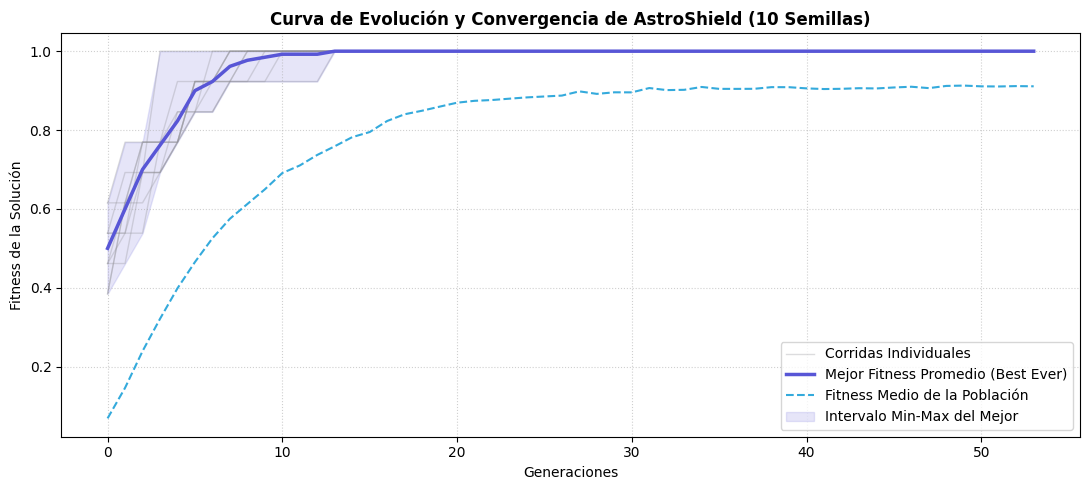

In [12]:
max_length = max(len(h) for h in all_histories)
generations_range = range(max_length)

best_curves, mean_curves = [], []
for hist in all_histories:
    # Se extiende la última generación si hubo parada anticipada, para promediar correctamente
    last_val = hist[-1]
    best_curves.append([g["best"] for g in hist] + [last_val["best"]] * (max_length - len(hist)))
    mean_curves.append([g["mean"] for g in hist] + [last_val["mean"]] * (max_length - len(hist)))

avg_best_curve = np.mean(best_curves, axis=0)
avg_mean_curve = np.mean(mean_curves, axis=0)

plt.figure(figsize=(11, 5), dpi=100)
for i, b_curve in enumerate(best_curves):
    plt.plot(generations_range, b_curve, color="#8E8E93", alpha=0.3, linewidth=1,
             label="Corridas Individuales" if i == 0 else "")
plt.plot(generations_range, avg_best_curve, label="Mejor Fitness Promedio (Best Ever)", color="#5856D6", linewidth=2.5)
plt.plot(generations_range, avg_mean_curve, label="Fitness Medio de la Población", color="#34AADC", linestyle="--", linewidth=1.5)
plt.fill_between(generations_range, np.min(best_curves, axis=0), np.max(best_curves, axis=0),
                 color="#5856D6", alpha=0.15, label="Intervalo Min-Max del Mejor")
plt.title("Curva de Evolución y Convergencia de AstroShield (10 Semillas)", fontsize=12, fontweight="bold")
plt.xlabel("Generaciones", fontsize=10)
plt.ylabel("Fitness de la Solución", fontsize=10)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


### Entregable 2: Etapa 3 - Simulación de Cambios Dinámicos

Simularemos una crisis geopolítica: la prioridad de la **Región del Sahel, África** escala de 2 a 5 y surge una **Nueva Zona de Exclusión de Interferencia Electromagnética** sobre el Atlántico Medio.

In [13]:
print("--- SIMULACIÓN DE CAMBIO DINÁMICO ---")

def coverage_summary(coords):
    sats = [(coords[2*i], coords[2*i+1]) for i in range(8)]
    st = region_coverage_status(sats)
    return [s["name"].split(",")[0] for s in st if s["covered"]], [s["name"].split(",")[0] for s in st if not s["covered"]]

# 1. Estado previo de la constelación optimizada
prev_fitness, prev_valid, _ = evaluate_configuration(best_individual)
print(f"Estado Inicial: Fitness anterior = {prev_fitness:.5f} | Validez = {prev_valid}")

# 2. Cambio drástico en el escenario global
print("\n[!] ALERTA: La prioridad del Sahel, África ha subido a 5 (Prioridad Extrema).")
REGIONS[3]["priority_weight"] = 5

print("[!] ALERTA: Nueva zona de exclusión detectada por basura espacial (Atlántico Medio).")
FORBIDDEN_ZONES.append({"name": "Interferencia Atlántico Medio", "lat": 30.0, "lon": -50.0, "radius": 15.0})

# 3. La constelación previa en el nuevo entorno
post_fitness, post_valid, post_viol = evaluate_configuration(best_individual)
covered_now, uncovered_now = coverage_summary(best_individual)
print("\nEvaluación inmediata del sistema sin adaptar:")
print(f"  - Nuevo Fitness sin adaptar: {post_fitness:.5f}")
print(f"  - ¿Sigue siendo válida la constelación?: {post_valid} (Violación acumulada: {post_viol:.2f}°)")
print(f"  - Regiones cubiertas   : {', '.join(covered_now) or '—'}")
print(f"  - Regiones no cubiertas: {', '.join(uncovered_now) or '—'}")

# 4. Re-adaptación evolutiva
print("\nRe-ejecutando el Algoritmo Genético en el nuevo entorno...")
adapted_fitness, adapted_individual, adapted_valid, adapted_viol, _ = genetic_algorithm(
    max_gens=100, random_state=42, **HP
)
covered_new, uncovered_new = coverage_summary(adapted_individual)
print("\nResultado tras la Re-adaptación Dinámica:")
print(f"  - Fitness de Constelación Adaptada: {adapted_fitness:.5f}")
print(f"  - ¿Es válida la nueva solución?: {adapted_valid} (Violación: {adapted_viol:.2f}°)")
print(f"  - Regiones cubiertas   : {', '.join(covered_new) or '—'}")
print(f"  - Regiones no cubiertas: {', '.join(uncovered_new) or '—'}")


--- SIMULACIÓN DE CAMBIO DINÁMICO ---
Estado Inicial: Fitness anterior = 1.00000 | Validez = True

[!] ALERTA: La prioridad del Sahel, África ha subido a 5 (Prioridad Extrema).
[!] ALERTA: Nueva zona de exclusión detectada por basura espacial (Atlántico Medio).

Evaluación inmediata del sistema sin adaptar:
  - Nuevo Fitness sin adaptar: 1.00000
  - ¿Sigue siendo válida la constelación?: True (Violación acumulada: 0.00°)
  - Regiones cubiertas   : Península de Yucatán, Amazonía brasileña, California, Región del Sahel, Japón, Interior de Australia
  - Regiones no cubiertas: —

Re-ejecutando el Algoritmo Genético en el nuevo entorno...

Resultado tras la Re-adaptación Dinámica:
  - Fitness de Constelación Adaptada: 1.00000
  - ¿Es válida la nueva solución?: True (Violación: 0.00°)
  - Regiones cubiertas   : Península de Yucatán, Amazonía brasileña, California, Región del Sahel, Japón, Interior de Australia
  - Regiones no cubiertas: —


### Entregable 3: Exportación de Datos a `astroshield_data.json` y Visualizador 3D/2D

El JSON desacopla el motor de la interfaz. Incluye, por región, si está **cubierta o no cubierta** (calculado con la misma función en km que usa el fitness) tanto para la constelación inicial como para la optimizada. El visor solo dibuja esos datos.

In [14]:
colors = ["#FF3B30", "#4CD964", "#007AFF", "#FFCC00", "#5856D6", "#FF9500", "#34AADC", "#FF2D55"]

# Constelación inicial (aleatoria y reparada) para la comparación visual
np.random.seed(1234)
initial_coords = []
for _ in range(8):
    lat, lon = sample_sphere_point_uniform()
    initial_coords.extend([lat, lon])
initial_coords = process_and_repair_individual(initial_coords)

initial_fitness, initial_valid, _ = evaluate_configuration(initial_coords)
init_status = region_coverage_status([(initial_coords[2*i], initial_coords[2*i+1]) for i in range(8)])
opt_status = region_coverage_status([(adapted_individual[2*i], adapted_individual[2*i+1]) for i in range(8)])

data_to_export = {
    "params": {
        "earth_radius_km": R_EARTH,
        "footprint_km": SAT_FOOTPRINT_RADIUS_KM,
        "region_radius_km": REGION_RADIUS_KM
    },
    "satellites_initial": [
        {"id": s + 1, "lat": initial_coords[2*s], "lon": initial_coords[2*s+1], "color": "#999999"}
        for s in range(8)
    ],
    "satellites_optimized": [
        {"id": s + 1, "lat": adapted_individual[2*s], "lon": adapted_individual[2*s+1], "color": colors[s]}
        for s in range(8)
    ],
    "regions": [
        {
            "name": r["name"], "lat": r["lat"], "lon": r["lon"], "weight": r["priority_weight"],
            "covered_initial": bool(si["covered"]), "nearest_km_initial": round(si["nearest_km"], 1),
            "covered_optimized": bool(so["covered"]), "nearest_km_optimized": round(so["nearest_km"], 1)
        } for r, si, so in zip(REGIONS, init_status, opt_status)
    ],
    "forbidden": [
        {"name": f["name"], "lat": f["lat"], "lon": f["lon"], "radius": f["radius"]}
        for f in FORBIDDEN_ZONES
    ],
    "metrics": {
        "initial_fitness": float(initial_fitness),
        "optimized_fitness": float(adapted_fitness),
        "is_valid": bool(adapted_valid)
    }
}

with open("astroshield_data.json", "w") as f:
    json.dump(data_to_export, f, indent=2)

print("Archivo 'astroshield_data.json' exportado exitosamente.")
print(f"Fitness constelación inicial: {initial_fitness:.5f} | optimizada: {adapted_fitness:.5f}")


Archivo 'astroshield_data.json' exportado exitosamente.
Fitness constelación inicial: 0.00000 | optimizada: 1.00000
